 ЛАБОРАТОРНАЯ РАБОТА № 3.1: ИНТЕРПОЛЯЦИЯ МНОГОЧЛЕНАМИ ЛАГРАНЖА И НЬЮТОНА
Функция: f(x) = cos(x) + x
Исследуемый набор узлов: Набор (б): [0, π/6, 5π/12, π/2]

------------------------------------------------------------------------------------------
1. ИСХОДНЫЕ УЗЛЫ ИНТЕРПОЛЯЦИИ И ЗНАЧЕНИЯ ФУНКЦИИ
------------------------------------------------------------------------------------------
i    | Обозначение  | x_i (число)    | y_i = f(x_i)    
------------------------------------------------------------------------------------------
0    | 0            | 0.000000       | 1.000000        
1    | π/6          | 0.523599       | 1.389624        
2    | 5π/12        | 1.308997       | 1.567816        
3    | π/2          | 1.570796       | 1.570796        

------------------------------------------------------------------------------------------
2. ИНТЕРПОЛЯЦИОННЫЙ МНОГОЧЛЕН ЛАГРАНЖА L_n(x)
------------------------------------------------------------------------------------------
L_n(x) = -0

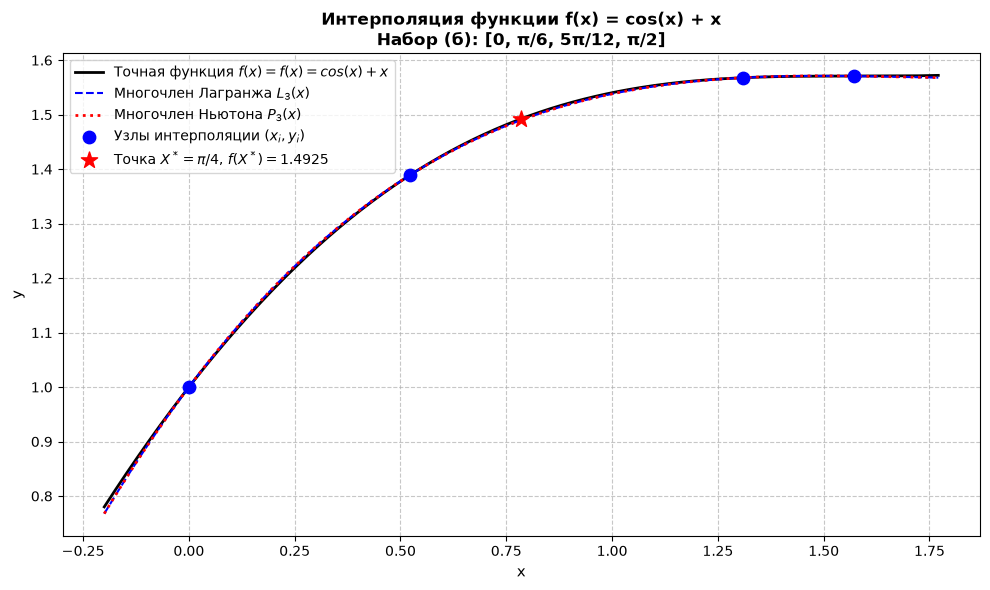

In [ ]:
import math
import os
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np


class InterpolationTask:
    """
    Функция f(x) = cos(x) + x
    """

    def __init__(self, dataset_type='a'):
        self.name = "f(x) = cos(x) + x"
        self.f = lambda x: math.cos(x) + x
        
        self.M4 = 1.0
        self.X_star = math.pi / 4.0  # 0.785398
        
        if dataset_type == 'a':
            self.nodes = [0.0, math.pi / 6.0, math.pi / 3.0, math.pi / 2.0]
            self.node_names = ["0", "π/6", "π/3", "π/2"]
            self.dataset_title = "Набор (а): [0, π/6, π/3, π/2]"
        else:
            self.nodes = [0.0, math.pi / 6.0, 5.0 * math.pi / 12.0, math.pi / 2.0]
            self.node_names = ["0", "π/6", "5π/12", "π/2"]
            self.dataset_title = "Набор (б): [0, π/6, 5π/12, π/2]"
            
        self.y_vals = [self.f(x) for x in self.nodes]


def lagrange_basis(x, nodes, i):
    """Вычисление базисного многочлена l_i(x)"""

    n = len(nodes)
    l_i = 1.0

    for j in range(n):
        if i != j:
            l_i *= (x - nodes[j]) / (nodes[i] - nodes[j])

    return l_i


def lagrange_interpolate(x, nodes, y_vals):
    """Вычисление значения многочлена Лагранжа L_n(x)"""

    n = len(nodes)
    return sum(y_vals[i] * lagrange_basis(x, nodes, i) for i in range(n))


def format_lagrange_polynomial(nodes, y_vals):
    """Форматированный вывод явного вида многочлена Лагранжа"""

    n = len(nodes)
    terms = []

    for i in range(n):
        num_factors = [f"(x - {nodes[j]:.4f})" for j in range(n) if i != j]
        denom = 1.0

        for j in range(n):
            if i != j:
                denom *= (nodes[i] - nodes[j])

        coeff = y_vals[i] / denom
        terms.append(f"{coeff:+.6f} * " + "".join(num_factors))

    return "L_n(x) = " + "\n         ".join(terms)


def compute_divided_differences(nodes, y_vals):
    """
    Построение полной таблицы разделенных разностей.
    """

    n = len(nodes)
    dd = [[0.0] * n for _ in range(n)]
    for i in range(n):
        dd[i][0] = y_vals[i]

    for j in range(1, n):
        for i in range(n - j):
            dd[i][j] = (dd[i+1][j-1] - dd[i][j-1]) / (nodes[i+j] - nodes[i])

    return dd


def newton_interpolate(x, nodes, dd):
    """Вычисление значения многочлена Ньютона P_n(x)"""

    n = len(nodes)
    val = dd[0][0]
    prod = 1.0

    for i in range(1, n):
        prod *= (x - nodes[i-1])
        val += dd[0][i] * prod

    return val


def format_newton_polynomial(nodes, dd):
    """Форматированный вывод явного вида многочлена Ньютона"""

    n = len(nodes)
    terms = [f"{dd[0][0]:.6f}"]
    prod_str = ""

    for i in range(1, n):
        prod_str += f"(x - {nodes[i-1]:.4f})"
        coeff = dd[0][i]
        terms.append(f"{coeff:+.6f} * {prod_str}")

    return "P_n(x) = " + " ".join(terms)


def compute_omega(x, nodes):
    """Вычисление узлового многочлена omega_{n+1}(x) = (x - x_0)...(x - x_n)"""
    prod = 1.0
    for x_i in nodes:
        prod *= (x - x_i)
    return prod


def theoretical_error_bound(x, nodes, M_next):
    """Априорная мажорантная оценка погрешности: (M_{n+1} / (n+1)!) * |omega_{n+1}(x)|"""
    n = len(nodes)
    omega_val = abs(compute_omega(x, nodes))
    return (M_next / math.factorial(n)) * omega_val


def plot_interpolation_results(task, dd):
    """
    Строит и сохраняет единый график с исходной функцией,
    многочленами Лагранжа и Ньютона, узлами и контрольной точкой X*.
    """
    x_min, x_max = min(task.nodes) - 0.2, max(task.nodes) + 0.2
    x_dense = np.linspace(x_min, x_max, 300)
    
    y_exact = [task.f(x) for x in x_dense]
    y_lagrange = [lagrange_interpolate(x, task.nodes, task.y_vals) for x in x_dense]
    y_newton = [newton_interpolate(x, task.nodes, dd) for x in x_dense]
    
    plt.figure(figsize=(10, 6))
    plt.plot(x_dense, y_exact, 'k-', linewidth=2, label=rf'Точная функция $f(x) = {task.name}$')
    plt.plot(x_dense, y_lagrange, 'b--', linewidth=1.5, label=r'Многочлен Лагранжа $L_3(x)$')
    plt.plot(x_dense, y_newton, 'r:', linewidth=2, label=r'Многочлен Ньютона $P_3(x)$')
    
    plt.scatter(task.nodes, task.y_vals, color='blue', s=80, zorder=5, label=r'Узлы интерполяции $(x_i, y_i)$')
    
    f_star = task.f(task.X_star)
    plt.scatter([task.X_star], [f_star], color='red', marker='*', s=150, zorder=6, label=rf'Точка $X^* = \pi/4$, $f(X^*) = {f_star:.4f}$')
    
    plt.title(f'Интерполяция функции {task.name}\n{task.dataset_title}', fontsize=12, fontweight='bold')
    plt.xlabel('x', fontsize=11)
    plt.ylabel('y', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(fontsize=10, loc='best')
    plt.tight_layout()
    
    plt.show()


def main(dataset_type='a'):
    task = InterpolationTask(dataset_type=dataset_type)
    dd = compute_divided_differences(task.nodes, task.y_vals)
    
    print("=" * 90)
    print(" ЛАБОРАТОРНАЯ РАБОТА № 3.1: ИНТЕРПОЛЯЦИЯ МНОГОЧЛЕНАМИ ЛАГРАНЖА И НЬЮТОНА")
    print("=" * 90)
    print(f"Функция: {task.name}")
    print(f"Исследуемый набор узлов: {task.dataset_title}\n")
    
    # 1. Таблица исходных узлов
    print("-" * 90)
    print("1. ИСХОДНЫЕ УЗЛЫ ИНТЕРПОЛЯЦИИ И ЗНАЧЕНИЯ ФУНКЦИИ")
    print("-" * 90)
    print(f"{'i':<4} | {'Обозначение':<12} | {'x_i (число)':<14} | {'y_i = f(x_i)':<16}")
    print("-" * 90)
    for i in range(len(task.nodes)):
        print(f"{i:<4} | {task.node_names[i]:<12} | {task.nodes[i]:<14.6f} | {task.y_vals[i]:<16.6f}")
    
    # 2. Многочлен Лагранжа
    print("\n" + "-" * 90)
    print("2. ИНТЕРПОЛЯЦИОННЫЙ МНОГОЧЛЕН ЛАГРАНЖА L_n(x)")
    print("-" * 90)
    print(format_lagrange_polynomial(task.nodes, task.y_vals))
    
    # 3. Таблица разделенных разностей
    print("\n" + "-" * 90)
    print("3. ТАБЛИЦА РАЗДЕЛЕННЫХ РАЗНОСТЕЙ")
    print("-" * 90)
    n = len(task.nodes)
    header = f"{'i':<3} | {'x_i':<10} | {'y_i (0-й)':<12}"
    for j in range(1, n):
        header += f" | {f'{j}-й порядок':<12}"
    print(header)
    print("-" * 90)
    for i in range(n):
        row_str = f"{i:<3} | {task.nodes[i]:<10.4f} | {dd[i][0]:<12.6f}"
        for j in range(1, n - i):
            row_str += f" | {dd[i][j]:<12.6f}"
        print(row_str)
        
    print("\n[Элементы верхней диагонали для многочлена Ньютона]:")
    for j in range(n):
        print(f"  f[x_0, ..., x_{j}] = {dd[0][j]:.6f}")
        
    # 4. Многочлен Ньютона
    print("\n" + "-" * 90)
    print("4. ИНТЕРПОЛЯЦИОННЫЙ МНОГОЧЛЕН НЬЮТОНА P_n(x)")
    print("-" * 90)
    print(format_newton_polynomial(task.nodes, dd))
    
    # 5. Вычисления в контрольной точке X*
    X_star = task.X_star
    f_star = task.f(X_star)
    L_star = lagrange_interpolate(X_star, task.nodes, task.y_vals)
    P_star = newton_interpolate(X_star, task.nodes, dd)
    
    abs_error_real = abs(f_star - P_star)
    abs_diff_methods = abs(L_star - P_star)
    theory_err = theoretical_error_bound(X_star, task.nodes, task.M4)
    
    print("\n" + "=" * 90)
    print(f"5. РЕЗУЛЬТАТЫ В КОНТРОЛЬНОЙ ТОЧКЕ X* = π/4 ≈ {X_star:.6f}")
    print("=" * 90)
    print(f"{'Показатель / Величина':<45} | {'Значение':<20}")
    print("-" * 90)
    print(f"{'Точное значение функции f(X*)':<45} | {f_star:<20.6f}")
    print(f"{'Значение многочлена Лагранжа L_3(X*)':<45} | {L_star:<20.6f}")
    print(f"{'Значение многочлена Ньютона P_3(X*)':<45} | {P_star:<20.6f}")
    print(f"{'Фактическая погрешность |f(X*) - P_3(X*)|':<45} | {abs_error_real:<20.6e}")
    print(f"{'Разность результатов |L_3(X*) - P_3(X*)|':<45} | {abs_diff_methods:<20.6e}")
    print(f"{'Теоретическая априорная оценка погрешности':<45} | {theory_err:<20.6e}")
    print("=" * 90)
    
    if abs_diff_methods < 1e-12:
        print("\n[ПРОВЕРКА СОВПАДЕНИЯ]: Результаты методов Лагранжа и Ньютона СОВПАДАЮТ с высокой точностью!")
    if abs_error_real <= theory_err:
        print("[ПРОВЕРКА ПОГРЕШНОСТИ]: Фактическая погрешность СТРОГО МЕНЬШЕ теоретической верхней границы.")

    # 6. Построение и сохранение графика
    plot_interpolation_results(task, dd)

if __name__ == '__main__':
    main(dataset_type='b')